# PhishGuard — Data Cleaning
**Dataset:** PhiUSIIL Phishing URL Dataset(UCI ML Repository, CC BY 4.0)

URL: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

**Output :** `data/cleaned_.csv`, `feature_groups_.json`, `cleaning_log.json`

In [ ]:
#libraries for saving logs,text patterns,unzipping, and downloading
import json, re, zipfile, urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#for scoreing how well 1 feature separates phishing from legitimates
from sklearn.metrics import roc_auc_score

#Show up to 60 cols wide
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
#Give all charts in white grid style
sns.set_theme(style="whitegrid")

#every decision/count inserted and saved
log = {}

#DATA_DIR_ is data folder, and raw_PATH_ is where raw CSV lives
DATA_DIR_ = Path("../data")   #DATA_DIR_ = Path("data")   
raw_PATH_ = DATA_DIR_ / "raw" / "PhiUSIIL_Phishing_URL_Dataset.csv"
UCI_ZIP_ = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"


## 0. Load raw_ data

In [27]:
if not raw_PATH_.exists():
    raw_PATH_.parent.mkdir(parents=True,exist_ok=True)
    zpath = raw_PATH_.parent / "phiusiil.zip"
    print("raw_ file 'not found', so downloading from UCI ....")
    urllib.request.urlretrieve(UCI_ZIP_,zpath)
    with zipfile.ZipFile(zpath) as z_:
        z_.extractall(raw_PATH_.parent)

raw_ = pd.read_csv(raw_PATH_,encoding="utf-8")
print("Shape : ", raw_.shape)

#storing 2 things in log dict, will as cleaning_log.json
log["raw__rows"],log["raw__cols"]=raw_.shape

raw_.head()

Shape :  (235795, 56)


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


## 1. Describe the dataset
- **Record** = one URL(web address visited)
- **Target** equals 'label'. In PhiUSIIL **1 = legitimate, 0 = phishing**. To align with the proposal, `is_phishing` (1 = phishing) is used as the positive class in Step 3.
- **Attributes** are divided into three groups : URL-only features, webpage(HTML) features, and
  bookkeeping (`FILENAME`). Step 7 removes the webpage's features and FILENAME.

In [28]:
#Count cols by type
display(raw_["label"].value_counts().to_frame("rows"))
print("\n")

#Count rows per class(1 = legitimate & 0 = phishing)
print("Label counts: (1= legitimate, 0= phishing):")
print(raw_["label"].value_counts().rename_axis(None).to_string())
print("\n")

# == 0 marks phishing rows as "True"
# {:.1%} prints it as %
print("\nPhishing share: {:.1%}".format((raw_["label"] == 0).mean()))

,rows
label,
1,134850
0,100945




Label counts: (1= legitimate, 0= phishing):
1    134850
0    100945



Phishing share: 42.8%


In [29]:
#Attribute types --> (nominal / discrete / binary  / continuous)
def attr_type(s):
    if s.dtype == object or str(s.dtype).startswith("str"):  # text col
        return "nominal"
    if s.nunique() <= 2:  # binary
        return "binary"
    if pd.api.types.is_integer_dtype(s):  # whole numbers
        return "discrete"
    return "continuous"  # anything else


types = pd.DataFrame({
    "dtype": raw_.dtypes.astype(str),
    "type": [attr_type(raw_[c]) for c in raw_],  # table with 1 row per colum
    "n_unique": raw_.nunique(),
})

#count no. of cols fall in each category
types["type"].value_counts()

,count
type,
discrete,21
binary,20
continuous,10
nominal,5


## 2. Missing values
1. real `NaN` empty
2. empty text or whitespace string("" or " ")
3. -1 in count col

In [30]:
text_cols_ = [c for c in raw_.columns if raw_[c].dtype == object or str(raw_[c].dtype).startswith("str")]
num_cols_ = raw_.select_dtypes("number").columns.tolist()

#Sum of all 3 missing_ values
nan_counts = raw_.isna().sum()
empty_counts = pd.Series({c: (raw_[c].astype(str).str.strip() == "").sum() for c in text_cols_})
sentinel_counts = (raw_[num_cols_] < 0).sum()

missing_ = pd.DataFrame({"NaN": nan_counts,
                        "empty_string": empty_counts,
                        "negative_sentinel": sentinel_counts}).fillna(0).astype(int)

missing_["total"] = missing_.sum(axis=1)
print("Columns with any  missing_ value:")
display(missing_[missing_["total"] > 0]) if missing_["total"].any() else print("none")
log["missing__cells_total"] = int(missing_["total"].sum())

Columns with any  missing_ value:
none


`Title` legitimately have empty strings for pages without `<title>` element; it is a webpage feature and is dropped in Step 7
- If more than half of a row's values are missing, drop it
- numeric col to **median** (URL counts are highly right-skewed, so mean is not an appropriate choice)
- categorical col to **mode**

In [31]:
def handle_missing_(df_, cols, row_thresh=0.5):
    df_ = df_.copy()
    before = len(df_)
    # drop row if more than 50% of its cells are empty
    df_ = df_[df_[cols].isna().mean(axis=1) <= row_thresh]

    filled = {}  # record method used and no of cells fixed
    for i in cols:
        n = int(df_[i].isna().sum())
        if n == 0:
            continue
            #Number col: fill gaps with the median
        if pd.api.types.is_numeric_dtype(df_[i]):
            df_[i] = df_[i].fillna(df_[i].median());
            filled[i] = ("median", n)
        else: #Text col: fill gaps with the mode
            df_[i] = df_[i].fillna(df_[i].mode()[0]);
            filled[i] = ("mode", n)

    # return table, rows dropped, and record of fixes
    return df_, before-len(df_),filled

df_, rows_dropped_, filled_ = handle_missing_(raw_, [c for c in raw_.columns if c != "Title"])
print(f"Rows dropped for missingness are : {rows_dropped_}")
print(f"Columns modified: {filled_ if filled_ else 'none'}")
log["missing_rows_dropped"], log["missing_imputed"] = rows_dropped_, filled_

Rows dropped for missingness are : 0
Columns modified: none


## 3. Format fixing
- Remove the surrounding whitespace from the URL, domain, or TLD
- lowercase the **scheme and host only**,
- lowercase `Domain` and `TLD`,
- convert binary flags to `int8`(e.g. IsHTTP),
- change `label` with `is_phishing` (1 = phishing),
- report any text-encoding currupt (mojibake such as `Ã£`).The mojibake URLs are kept as it is.

In [32]:
def normalize_url(u_):
    u_ = u_.strip()
    m_ = re.match(r"^([A-Za-z][A-Za-z0-9+.-]*://)([^/?#]*)(.*)$", u_)
    if not m_:
        return u_
    scheme, host, rest = m_.groups()
    return scheme.lower() + host.lower() + rest

changed_ = {}
for c in ["URL", "Domain", "TLD"]:
    before = df_[c].copy()
    df_[c] = df_[c].astype(str).str.strip()
    if c == "URL":
        df_[c] = df_[c].map(normalize_url)
    else:
        df_[c] = df_[c].str.lower()
    changed_[c] = int((before != df_[c]).sum())
print("Values changed by normalization:", changed_)
log["format_values_changed"] = changed_


# Target re-coding (Phishing was 0, now it is 1)
df_["is_phishing"] = (df_["label"] == 0).astype("int8")
assert df_["is_phishing"].sum() == (raw_["label"] == 0).sum()
df_ = df_.drop(columns="label")

# Binary flags -> int8
binary_cols_ = [c for c in df_.select_dtypes("number") if set(df_[c].unique()) <= {0, 1}]
df_[binary_cols_] = df_[binary_cols_].astype("int8")
print(f"binary columns cast to int8: {len(binary_cols_)}")

# Encoding damage
moj_ = df_["URL"].str.contains("Ã|Â|â€", regex=True)
print(f"\nURLs with mojibake are : {moj_.sum()}")
display(df_.loc[moj_, ["URL", "is_phishing"]])

log["mojibake_urls"] = int(moj_.sum())

Values changed by normalization: {'URL': 0, 'Domain': 0, 'TLD': 0}
binary columns cast to int8: 20

URLs with mojibake are : 2


,URL,is_phishing
127839,https://22017-5502.s3.webspace.re/privatkunden...,1
158380,https://vinted.6545657.xyz/p5ci5kt9Ã¢â‚¬â€¹Ã¢â...,1


## 4. validity checks
Each column must satisfy these checks. Violation of it is data-entry error (fix / drop).

In [33]:
#picking cols by name...to save typing each col later
count_cols_ = [c for c in df_.columns if c.startswith("NoOf") or c in
              ("URLLength", "DomainLength", "TLDLength", "LineOfCode", "LargestLineLength")]
ratio_cols_ = [c for c in df_.columns if re.search(r"Ratio|Rate|Prob", c)]

checks_ = {
    "counts are non-negative ":     (df_[count_cols_] < 0).any(axis=1),
    "ratios/probs in [0, 1] ":      ((df_[ratio_cols_] < 0) | (df_[ratio_cols_] > 1)).any(axis=1),
    "URLSimilarityIndex in [0,100]": ~df_["URLSimilarityIndex"].between(0, 100),
    "DomainLength == len(Domain)": df_["DomainLength"] != df_["Domain"].str.len(),
    "Domain ends with .TLD ":       ~df_.apply(lambda r: r["Domain"].endswith("." + r["TLD"]), axis=1),
    "URL has scheme ":            ~df_["URL"].str.match(r"^https?://"),
    "IsHTTPS matches scheme":      df_["IsHTTPS"] != df_["URL"].str.startswith("https://").astype(int),
    "letters+digits <= URLLength ": (df_["NoOfLettersInURL"] + df_["NoOfDegitsInURL"]) > df_["URLLength"],
}

validity_ = pd.Series({k: int(v.sum()) for k, v in checks_.items()}, name="violations")
display(validity_.to_frame())
invalid_rows_ = pd.concat(checks_.values(), axis=1).any(axis=1)
log["validity__violations"] = validity_.to_dict()

,violations
counts are non-negative,0
"ratios/probs in [0, 1]",0
"URLSimilarityIndex in [0,100]",0
DomainLength == len(Domain),0
Domain ends with .TLD,0
URL has scheme,0
IsHTTPS matches scheme,493
letters+digits <= URLLength,0


In [34]:
#checks : is URLLength col similar to actual length of URL-text?

diff_ = df_["URLLength"] - df_["URL"].str.len()
print(diff_.value_counts().head())

# outputs--> "dif. of length" verses "no. of columns having difference"..

-1     187149
 0      48644
-4          1
-35         1
Name: count, dtype: int64


`URLLength` is mostly **1 less** than `len(URL)`. The offset is similar for both
classes(phishing and legitimate URLs), so this col is kept unchanged_ instead of re-computation. Recomputing only this one
feature will make it inconsistent with the ratio features generated from it.


In [35]:
# Inspect failing rule before decision
bad_https_ = checks_["IsHTTPS matches scheme"]

#counts no. of phishing (1) and no. of legitimate (0). If they nearly all phishing, dropping them will effect the data.
print(df_.loc[bad_https_, "is_phishing"].value_counts().to_dict())
print("\n")


#small table of two things for the bad rows:
#  - IsHTTPS: what dataset says (1 or 0)
#   - URL.str[:5] :  first 5 chars of URL, which are either http: or https
print(pd.crosstab(df_.loc[bad_https_, "IsHTTPS"], df_.loc[bad_https_, "URL"].str[:5]))
# output: shows exactly how disagree_... URL starts with http:(so it is not secure), but IsHTTPS says 1


#show 3 example rows... .str[:110] cuts URL into 110 chars
df_.loc[bad_https_, ["URL", "IsHTTPS"]].head(3).assign(URL=lambda d: d.URL.str[:110])

{1: 493}


URL      http:
IsHTTPS       
1          493


,URL,IsHTTPS
401,http://43.134.167.94/servicelogin?passive=1209...,1
1205,http://43.128.92.128/servicelogin?passive=1209...,1
1362,http://43.134.167.94/v3/signin/identifier?dsh=...,1


Every `IsHTTPS` mismatch is a `http://` URL with query string `https://...`
 This is **feature-computation
error, not bad record**, so the value is repaired by the scheme instead of dropping the row.Dropping will remove 493 real phishing examples.

In [36]:
#giving True/False for each row, depends on whether the URL really starts with https://
df_["IsHTTPS"] = df_["URL"].str.startswith("https://").astype("int8")
log["IsHTTPS_corrected"] = int(bad_https_.sum())

#Re-run all rules, anything that is still failing (out of 8 violations) is dropped
invalid_rows_ = pd.concat([v for k, v in checks_.items() if k != "IsHTTPS matches scheme"], axis=1).any(axis=1)
df_ = df_[~invalid_rows_].copy()
print(f"Rows dropped as invalid: {int(invalid_rows_.sum())}  ->  {len(df_):,} rows remain")
log["invalid_rows__dropped"] = int(invalid_rows_.sum())

Rows dropped as invalid: 0  ->  235,795 rows remain


## 5. Duplicates
Checked on two levels:
- **full-row duplicates**
- **duplicate URLs**: visiting the same URL more than once

  For this project, the second category is most important. The proposal's core is domain-disjoint split. Repeated URLs would increase the random-split score, distorting the generalisation gap.


In [37]:
full_dups_ = int(df_.duplicated().sum())
url_dups_ = df_[df_["URL"].duplicated(keep=False)]


# grouping the copies by URL, then counting no. of different labels each URL has(nunique())
# If URL is labeled phishing each time, count is 1 --> fine
# If 1 copy says phishing and another says legitimate, count is 2 --> conflict ,have to decide which label is right
conflicts_ = int((url_dups_.groupby("URL")["is_phishing"].nunique() > 1).sum())

print(f"Full-row duplicates :          {full_dups_}")
print(f"Rows sharing a URL :           {len(url_dups_)}  ({url_dups_['URL'].nunique()} distinct URLs)")
print(f"URLs with conflicting labels : {conflicts_}")
print("Duplicate URLs by class :", url_dups_.drop_duplicates("URL")["is_phishing"]
     .map({1: "phishing", 0: "legitimate"}).value_counts().to_dict())

Full-row duplicates :          0
Rows sharing a URL :           850  (425 distinct URLs)
URLs with conflicting labels : 0
Duplicate URLs by class : {'phishing': 425}


In [38]:
# making list of number columns to compare. skipping those with phishing label...
feat_cols_ = [c for c in df_.select_dtypes("number").columns if c != "is_phishing"]

#For repeated URLs, which cols have diff numbers?
disagree_ = (url_dups_.groupby("URL")[feat_cols_].nunique() > 1).sum()
disagree_[disagree_ > 0].sort_values(ascending=False).to_frame("groups_disagreeing")


#"groups disagreeing"  means "no. of repeated URLs whose copies don't match in this col"

,groups_disagreeing
URLLength,425
LetterRatioInURL,424
SpacialCharRatioInURL,407
NoOfOtherSpecialCharsInURL,289
DegitRatioInURL,250
URLCharProb,136
NoOfLettersInURL,129
LargestLineLength,72
LineOfCode,37
NoOfExternalRef,27


Copies of same URL have slightly different `URLLength` and ratio values, so `df_.duplicated()` misses them. Because no URLs have conflicting labels, the **first occurrence** is kept while the rest are eliminated.

In [39]:
# removing repeated URLs, keeping first copy of each

before = len(df_)
df_ = df_.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)

log["duplicate_urls_dropped"] = before - len(df_)
log["full_row_duplicates"] = full_dups_
log["conflicting_label_urls"] = conflicts_

print(f"Dropped {before - len(df_)} duplicate-URL rows  ->  {len(df_):,} rows remain")

Dropped 425 duplicate-URL rows  ->  235,370 rows remain


## 6. outliers
Detect IQR and Z-score, then **investigate before removing**

In phishing detection, a URL that is abnormally long or contains special characters/digits is often a *signal* rather than an error.

In [40]:
# 10 numeric cols to check
outlier_cols_ = ["URLLength", "DomainLength", "NoOfSubDomain", "NoOfLettersInURL",
                "NoOfDegitsInURL", "NoOfEqualsInURL", "NoOfQMarkInURL",
                "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL", "NoOfObfuscatedChar"]

rows = []
for c in outlier_cols_:
    x = df_[c]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_out = (x < lo) | (x > hi)
    z_out = ((x - x.mean()) / x.std()).abs() >= 3
    rows.append({
        "feature": c, "Q1": q1, "Q3": q3, "upper_fence": hi, "max": x.max(),
        "IQR_outliers_": int(iqr_out.sum()),
        "IQR_%": round(100 * iqr_out.mean(), 2),
        "Z>=3_outliers_": int(z_out.sum()),
        "phishing_%_among_IQR_outliers_": round(100 * df_.loc[iqr_out, "is_phishing"].mean(), 1) if iqr_out.any() else np.nan,
    })
outliers_ = pd.DataFrame(rows).set_index("feature")
print(f"Overall phishing share: {100 * df_['is_phishing'].mean():.1f}%")
outliers_

Overall phishing share: 42.7%


,Q1,Q3,upper_fence,max,IQR_outliers_,IQR_%,Z>=3_outliers_,phishing_%_among_IQR_outliers_
feature,,,,,,,,
URLLength,23.0,34.0,50.5,6097,22362,9.50,2196,99.9
DomainLength,16.0,24.0,36.0,110,13372,5.68,3788,97.9
NoOfSubDomain,1.0,1.0,1.0,10,57228,24.31,7036,65.1
NoOfLettersInURL,10.0,20.0,35.0,5191,19541,8.30,2163,99.9
NoOfDegitsInURL,0.0,0.0,0.0,2011,51198,21.75,1456,93.0
NoOfEqualsInURL,0.0,0.0,0.0,176,5395,2.29,1820,100.0
NoOfQMarkInURL,0.0,0.0,0.0,4,6122,2.60,6122,100.0
NoOfAmpersandInURL,0.0,0.0,0.0,149,883,0.38,456,100.0
NoOfOtherSpecialCharsInURL,1.0,3.0,6.0,499,12315,5.23,2505,100.0


When an IQR fence is 0 (Q1 = Q3 = 0), any non-zero values are flagged as outliers_, resulting in a high IQR count for that columns. Z-score is used more strictly here(So relying on z-score).

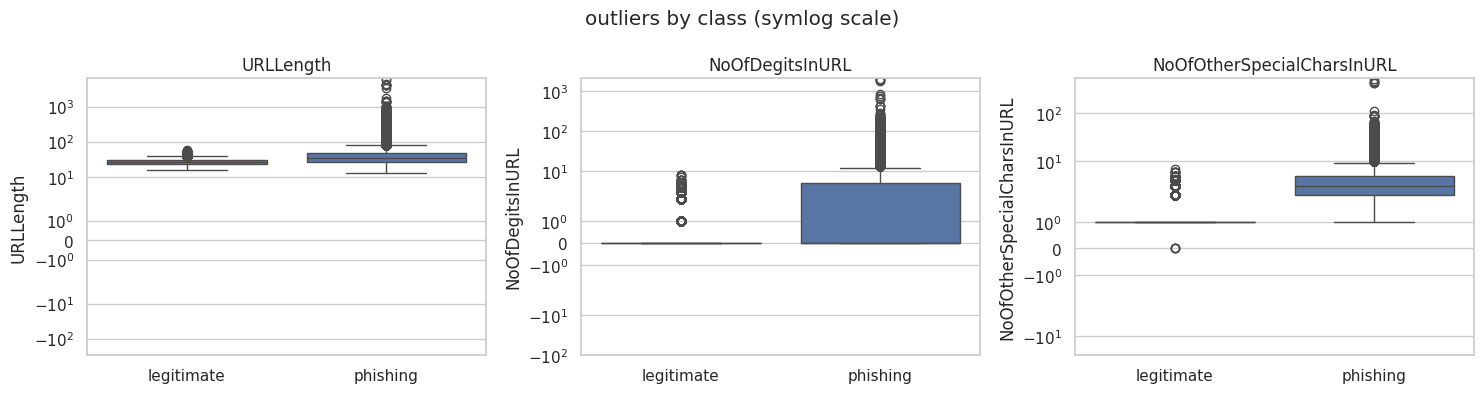

In [41]:
fig_, axes_ = plt.subplots(1, 3, figsize=(15, 4))
for ax_, c in zip(axes_, ["URLLength", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL"]):
    sns.boxplot(data=df_, x="is_phishing", y=c, ax=ax_, showfliers=True)
    ax_.set_yscale("symlog")
    ax_.set_xticks([0, 1], ["legitimate", "phishing"])
    ax_.set_xlabel("")
    ax_.set_title(c)
plt.suptitle("outliers by class (symlog scale)")
plt.tight_layout(); plt.show()

In [42]:
print("Longest URLs are :")
df_.nlargest(5, "URLLength")[["URL", "URLLength", "is_phishing"]].assign(URL=lambda d: d.URL.str[:90] + "...")

Longest URLs are :


,URL,URLLength,is_phishing
102859,https://xwebhostapp.github.io/freehost//#eyj2z...,6097,1
9650,https://b4e921f0.sso-mailsrvr-4344e5teed.pages...,5794,1
150704,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4274,1
145238,https://inspirationalatmospheres.com/qxzrrr%20...,4246,1
152564,https://bodhicardstech.com/beta/wx%20qz%20xx%2...,4054,1



**Decision: include all outliers_ in `cleaned_.csv`**
- None of them violated a validity_ criteria (Step 4), therefore they are actual observations, not entry errors.
- Phishing is over-represented in outliers_, and deleting them would eliminate the most difficult and informative phishing examples.
- Removing entire rows would also influence the domain-disjoint split.

The skew is real and negatively impacts distance and gradient-based algorithms, including Logistic Regression. That will be processed as a **transformation** in the preprocessing step. Doing so before the split would leak test-set statistics into training.

In [43]:
log["outlier_policy"] = "kept; transform (log1p/clip) in preprocessing after the split"
log["outlier_summary"] = outliers_[["IQR_outliers_", "Z>=3_outliers_"]].to_dict()

## 7. URL-only feature subset

The proposal limits primary models to features that can be computed using **only the URL string** before opening the page. This removes
- all webpage/HTML features (`LineOfCode`, `HasTitle`, `NoOfImage`, ...)
- `Title` (page text)
- `FILENAME` (bookkeeping, which leaks the label, see below)

In [44]:
url_features_ = ["URLLength", "DomainLength", "IsDomainIP", "TLD", "URLSimilarityIndex",
                "CharContinuationRate", "TLDLegitimateProb", "URLCharProb", "TLDLength",
                "NoOfSubDomain", "HasObfuscation", "NoOfObfuscatedChar", "ObfuscationRatio",
                "NoOfLettersInURL", "LetterRatioInURL", "NoOfDegitsInURL", "DegitRatioInURL",
                "NoOfEqualsInURL", "NoOfQMarkInURL", "NoOfAmpersandInURL",
                "NoOfOtherSpecialCharsInURL", "SpacialCharRatioInURL", "IsHTTPS"]
keep_cols_ = ["URL", "Domain"] + url_features_ + ["is_phishing"]
dropped_cols_ = [c for c in df_.columns if c not in keep_cols_]
print(f"Keeping {len(url_features_)} URL features (+ URL, Domain, target)")
print(f"Dropping {len(dropped_cols_)} columns:", dropped_cols_)

Keeping 23 URL features (+ URL, Domain, target)
Dropping 30 columns: ['FILENAME', 'LineOfCode', 'LargestLineLength', 'HasTitle', 'Title', 'DomainTitleMatchScore', 'URLTitleMatchScore', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup', 'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef', 'NoOfEmptyRef', 'NoOfExternalRef']


In [45]:
# FILENAME leaks the label: files prefixed 'oph' are all phishing
pd.crosstab(df_["FILENAME"].str.startswith("oph"), df_["is_phishing"],
            rownames=["FILENAME starts with 'oph'"], colnames=["is_phishing"])

is_phishing,0,1
FILENAME starts with 'oph',,
False,134850,92232
True,0,8288


### 7a. Leakage audit

Phishing is hard to detect. If a single column can almost precisely distinguish between phishing and legitimate, something is likely wrong. Real phishing detection requires a combination of several signs.

The dataset represents how it was acquired rather than what phishing is, and may not be applicable to new domains. Each numeric URL attribute is rated individually using ROC-AUC (0.5 = worthless, 1.0 = great).

In [46]:
auc = {}  #empty dict to store the score of each col
for c in [f for f in url_features_ if f != "TLD"]:
    a = roc_auc_score(df_["is_phishing"], df_[c])
    auc[c] = max(a, 1 - a)
auc = pd.Series(auc).sort_values(ascending=False).round(4)
auc.head(10).to_frame("single-feature AUC")

,single-feature AUC
URLSimilarityIndex,0.9961
NoOfOtherSpecialCharsInURL,0.8232
SpacialCharRatioInURL,0.8071
URLCharProb,0.7676
IsHTTPS,0.7568
CharContinuationRate,0.7435
NoOfLettersInURL,0.7416
URLLength,0.7317
NoOfDegitsInURL,0.7277
DegitRatioInURL,0.7258


In [47]:
legit = df_[df_.is_phishing == 0]
phish = df_[df_.is_phishing == 1]
host_path_ = lambda s: s.str.replace(r"^https?://", "", regex=True)
artifacts_ = pd.DataFrame({
    "legitimate": [legit.URL.str.startswith("https://www.").mean(),
                   (legit.URLSimilarityIndex == 100).mean(),
                   legit.IsHTTPS.mean(),
                   host_path_(legit.URL).str.contains("/").mean()],
    "phishing":   [phish.URL.str.startswith("https://www.").mean(),
                   (phish.URLSimilarityIndex == 100).mean(),
                   phish.IsHTTPS.mean(),
                   host_path_(phish.URL).str.contains("/").mean()],
}, index=["starts with https://www.", "URLSimilarityIndex == 100", "IsHTTPS == 1", "has a path after host"])
(artifacts_ * 100).round(1).astype(str) + "%"

,legitimate,phishing
starts with https://www.,100.0%,2.4%
URLSimilarityIndex == 100,100.0%,0.8%
IsHTTPS == 1,100.0%,48.6%
has a path after host,0.0%,59.7%



**Findings requires to know:**
1. All legitimate URLs are of the form `https://www.<domain>`, with HTTPS, `www.`, and no path. Phishing URLs are far more different. This would fail on new real-world data, where legitimate sites also have paths.
2. The dataset authors calculated `TLDLegitimateProb` and `URLCharProb` for all rows, including those that would subsequently become test set. This means that test information is leaked into training.
3. The decision. Keep these features in `cleaned_.csv`, but tag them `leak_suspect` in `feature_groups_.json`. So models are trained both with and without them, and both results are published.


In [48]:
feature_groups_ = {
    "target": "is_phishing",
    "id_columns": ["URL", "Domain"],
    "categorical": ["TLD"],
    "domain_tld": ["DomainLength", "IsDomainIP", "TLD", "TLDLength", "NoOfSubDomain", "TLDLegitimateProb"],
    "char_ratio": ["LetterRatioInURL", "DegitRatioInURL", "SpacialCharRatioInURL",
                   "ObfuscationRatio", "CharContinuationRate", "URLCharProb"],
    "char_count": ["URLLength", "NoOfLettersInURL", "NoOfDegitsInURL", "NoOfEqualsInURL",
                   "NoOfQMarkInURL", "NoOfAmpersandInURL", "NoOfOtherSpecialCharsInURL",
                   "NoOfObfuscatedChar", "HasObfuscation"],
    "similarity": ["URLSimilarityIndex"],
    "protocol": ["IsHTTPS"],
    "leak_suspect": ["URLSimilarityIndex", "TLDLegitimateProb", "URLCharProb", "IsHTTPS"],
    "notes": {
        "label_meaning": "is_phishing: 1 = phishing, 0 = legitimate (original 'label' was inverted)",
        "leak_suspect": "near-perfect separators or computed over the full dataset; report models with and without",
        "url_artifact": "all legitimate URLs are bare https://www.<domain> homepages",
        "outliers_": "kept; apply log1p/clip in preprocessing, fitted on train split only",
        "URLLength": "authors' value is usually len(URL) - 1; left unchanged_",
    },
}
grouped = set(sum([v for k, v in feature_groups_.items() if k in
                   ("domain_tld", "char_ratio", "char_count", "similarity", "protocol")], []))
assert grouped == set(url_features_), set(url_features_) ^ grouped  #checks that this set equals your full list of 23 features

## 8. Save outputs

In [51]:
cleaned_ = df_[keep_cols_].copy()

assert cleaned_.isna().sum().sum() == 0
assert not cleaned_["URL"].duplicated().any()
assert set(cleaned_["is_phishing"].unique()) == {0, 1}

DATA_DIR_.mkdir(exist_ok=True)
cleaned_.to_csv(DATA_DIR_ / "cleaned_.csv", index=False)
(DATA_DIR_ / "feature_groups_.json").write_text(json.dumps(feature_groups_, indent=2))

log.update({
    "final_rows": len(cleaned_), "final_cols": cleaned_.shape[1],
    "final_phishing": int(cleaned_.is_phishing.sum()),
    "final_legitimate": int((cleaned_.is_phishing == 0).sum()),
    "distinct_domains": int(cleaned_.Domain.nunique()),
    "single_feature_auc_top5": auc.head(5).to_dict(),
})
(DATA_DIR_ / "cleaning_log.json").write_text(json.dumps(log, indent=2, default=str))
print(f"Saved data/cleaned_.csv  {cleaned_.shape}")

Saved data/cleaned_.csv  (235370, 26)


In [53]:
summary = pd.DataFrame([
    ("raw_ rows", log["raw__rows"]),
    ("Rows dropped – missing_ values", log["missing_rows_dropped"]),
    ("IsHTTPS values corrected", log["IsHTTPS_corrected"]),
    ("Rows dropped – invalid values", log["invalid_rows__dropped"]),
    ("Rows dropped – duplicate URLs", log["duplicate_urls_dropped"]),
    ("Final rows", log["final_rows"]),
    ("  phishing", log["final_phishing"]),
    ("  legitimate", log["final_legitimate"]),
    ("Distinct domains", log["distinct_domains"]),
    ("Columns: raw_ → cleaned_", f'{log["raw__cols"]} → {log["final_cols"]}'),
], columns=["Step", "Value"]).set_index("Step")
summary

,Value
Step,
raw_ rows,235795
Rows dropped – missing_ values,0
IsHTTPS values corrected,493
Rows dropped – invalid values,0
Rows dropped – duplicate URLs,425
Final rows,235370
phishing,100520
legitimate,134850
Distinct domains,220086



  ### Notes
- **(EDA)**:

--Load `data/cleaned_.csv`. The target is `is_phishing`  (1=phishing). The leakage
  table in 7a deserves its own plot as it is one of the most intriguing results in the data.


  - **(preprocessing):**:
  
  -- Obtain the actual website name. The `Domain` column may appear as `www.example.co.uk` or `login.example.co.uk`. Both are part of the same website, `example.co.uk`.
  
 -- Clean the name with the `tldextract` tool before splitting it for training and testing.
When scaling, clipping, or applying log1p, use only the training rows to calculate the settings.

-- Use feature `groupings.json`. It lists which features go together. Use it to eliminate one group at a time , and train with and without `leak_suspect` runs.